# Vision — Menghitung Objek dengan Detektor (YOLOv8n pretrained COCO)
**Kapan dipakai:** jumlah orang di antrean/keramaian, kendaraan di jalan, buah di pohon,
ternak di kandang.

**Langkah:** YOLO mendeteksi kotak tiap objek → kotak kelas yang dicari dihitung per gambar.
Dua ambang dicari dari data latih agar MAE terkecil: keyakinan minimum dan tinggi kotak minimum
(orang kecil di latar belakang sering tidak ikut dihitung di label).

**Data demo:** PennFudan (`jumlah` pejalan kaki per foto). Kelas COCO: 0 = person, 2 = car,
dst. Mau fine-tune YOLO? Lihat `vision/deteksi`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/regresi"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/pennfudan_train.csv"
TEST_CSV = f"{DATA_FOLDER}/pennfudan_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/pennfudan_test_labels.csv"   # hanya ada di data latihan
IMAGE_FOLDER = "../../../data_latihan/vision/detection/PennFudanPed"
WEIGHTS = "../../../pretrained/yolov8n/yolov8n.pt"

PATH_COL = "path"       # path gambar, relatif terhadap IMAGE_FOLDER
TARGET = "jumlah"
COCO_CLASSES = [0]      # kelas COCO yang dihitung (0 = person)
IMAGE_SIZE = 640        # 960 untuk objek kecil/jauh, 320 untuk lebih cepat
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts().sort_index())
train.head()

train: (120, 3) | test: (50, 2)
jumlah
1    41
2    26
3    25
4    12
5     9
6     4
7     2
8     1
Name: count, dtype: int64


,id,path,jumlah
0,0,PNGImages/FudanPed00001.png,2
1,1,PNGImages/FudanPed00002.png,1
2,2,PNGImages/FudanPed00003.png,1
3,3,PNGImages/FudanPed00004.png,2
4,4,PNGImages/FudanPed00005.png,2


## Deteksi semua gambar sekali (ambang rendah 0.05), simpan tiap kotak
Satu baris per kotak: path, keyakinan, tinggi kotak relatif terhadap tinggi gambar (0–1).

In [4]:
model = YOLO(WEIGHTS)


def detect_boxes(paths):
    rows = []
    for path in paths:
        image_results = model.predict(f"{IMAGE_FOLDER}/{path}", imgsz=IMAGE_SIZE, conf=0.05,
                                      classes=COCO_CLASSES, device=DEVICE, verbose=False)
        boxes = image_results[0].boxes
        image_height = image_results[0].orig_shape[0]
        for box, confidence in zip(boxes.xyxy.tolist(), boxes.conf.tolist()):
            box_height = (box[3] - box[1]) / image_height
            rows.append([path, confidence, box_height])
    return pd.DataFrame(rows, columns=["path", "conf", "tinggi_rel"])


train_boxes = detect_boxes(train[PATH_COL])
test_boxes = detect_boxes(test[PATH_COL])
print("kotak train:", len(train_boxes), "| kotak test:", len(test_boxes))
train_boxes.describe().round(3)

kotak train: 915 | kotak test: 326


,conf,tinggi_rel
count,915.000,915.000
mean,0.446,0.377
std,0.343,0.260
min,0.050,0.022
25%,0.098,0.129
50%,0.342,0.332
75%,0.833,0.619
max,0.939,0.949


## Hitung objek per gambar dengan ambang tertentu

In [5]:
def count_objects(boxes, paths, min_confidence, min_height):
    chosen = boxes[(boxes["conf"] >= min_confidence) & (boxes["tinggi_rel"] >= min_height)]
    per_image = chosen["path"].value_counts()
    counts = []
    for path in paths:
        counts.append(per_image.get(path, 0))     # gambar tanpa kotak = 0
    return np.array(counts)


default_counts = count_objects(train_boxes, train[PATH_COL], 0.25, 0.0)
print("MAE ambang bawaan (conf 0.25):", round(mean_absolute_error(train[TARGET],
                                                                   default_counts), 4))

MAE ambang bawaan (conf 0.25): 1.675


## Cari ambang keyakinan dan tinggi minimum dari data latih (MAE terkecil)

In [6]:
best_mae = 1e9
for min_confidence in np.arange(0.1, 0.81, 0.05):
    for min_height in [0.0, 0.1, 0.2, 0.3, 0.4]:
        counts = count_objects(train_boxes, train[PATH_COL], min_confidence, min_height)
        mae = mean_absolute_error(train[TARGET], counts)
        if mae < best_mae:
            best_mae = mae
            BEST_CONFIDENCE = min_confidence
            BEST_HEIGHT = min_height
print("ambang terbaik: conf", round(BEST_CONFIDENCE, 2), "| tinggi min", BEST_HEIGHT,
      "| MAE", round(best_mae, 4))

ambang terbaik: conf 0.7 | tinggi min 0.3 | MAE 0.3667


## Evaluasi: asli vs hitungan + contoh kotak

hitung   1   2   3  4  5  6  7  8
asli                             
1       37   4   0  0  0  0  0  0
2        1  21   3  1  0  0  0  0
3        1   3  16  3  1  1  0  0
4        0   0   3  8  1  0  0  0
5        0   0   2  1  4  2  0  0
6        0   0   0  0  0  2  2  0
7        0   0   0  0  1  0  0  1
8        0   0   1  0  0  0  0  0

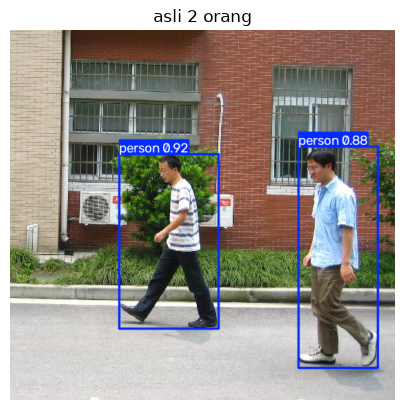

In [7]:
train_counts = count_objects(train_boxes, train[PATH_COL], BEST_CONFIDENCE, BEST_HEIGHT)
print(pd.crosstab(train[TARGET], train_counts, rownames=["asli"], colnames=["hitung"]))

first_path = train.loc[0, PATH_COL]
first_result = model.predict(f"{IMAGE_FOLDER}/{first_path}", imgsz=IMAGE_SIZE,
                             conf=BEST_CONFIDENCE, classes=COCO_CLASSES, device=DEVICE,
                             verbose=False)
plt.imshow(first_result[0].plot()[:, :, ::-1])     # plot() memberi BGR → dibalik ke RGB
plt.title(f"asli {train.loc[0, TARGET]} orang")
plt.axis("off")
plt.show()

## Prediksi test + submission (ambang dari data latih)

In [8]:
predictions = count_objects(test_boxes, test[PATH_COL], BEST_CONFIDENCE, BEST_HEIGHT)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["jumlah"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,jumlah
0,120,4
1,121,4
2,122,5
3,123,2
4,124,4


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [9]:
test_key = pd.read_csv(TEST_KEY_CSV)["jumlah"]
print("MAE test (kunci latihan):", round(mean_absolute_error(test_key, predictions), 4))

MAE test (kunci latihan): 0.26
